## 4.0. Key visualizations
Hier werden alle benötigten Pakete geladen. Und die Datei merged.csv importiert

In [2]:
import pandas as pd
from functools import reduce
import matplotlib.pyplot as plt

merged = pd.read_csv("merged.csv")

## 4.1. Zusammenhang "Economic Freedom and Happiness"

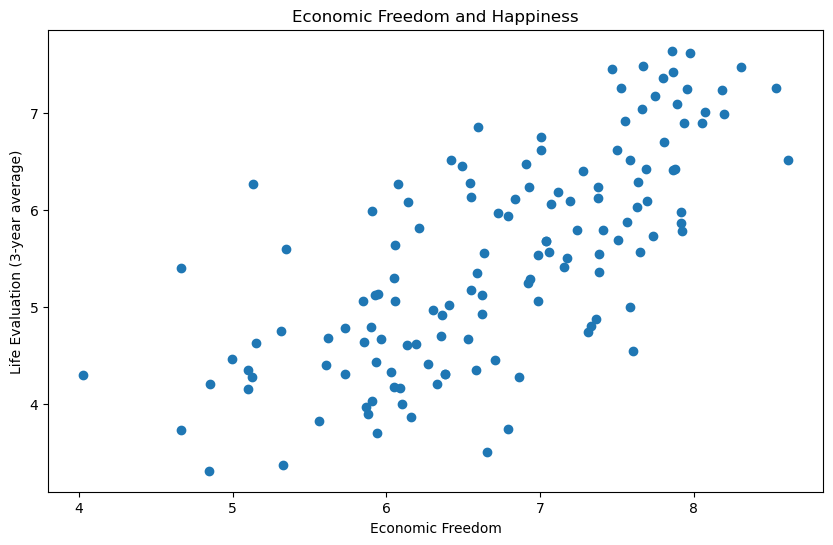

In [3]:
plt.figure(figsize=(10,6))

plt.scatter(
    merged["efotw_summary"],
    merged["life_evaluation_(3-year_average)"]
)

plt.xlabel("Economic Freedom")
plt.ylabel("Life Evaluation (3-year average)")
plt.title("Economic Freedom and Happiness")

plt.show()

## 4.1. Zusammenhang HDI_Rang und 

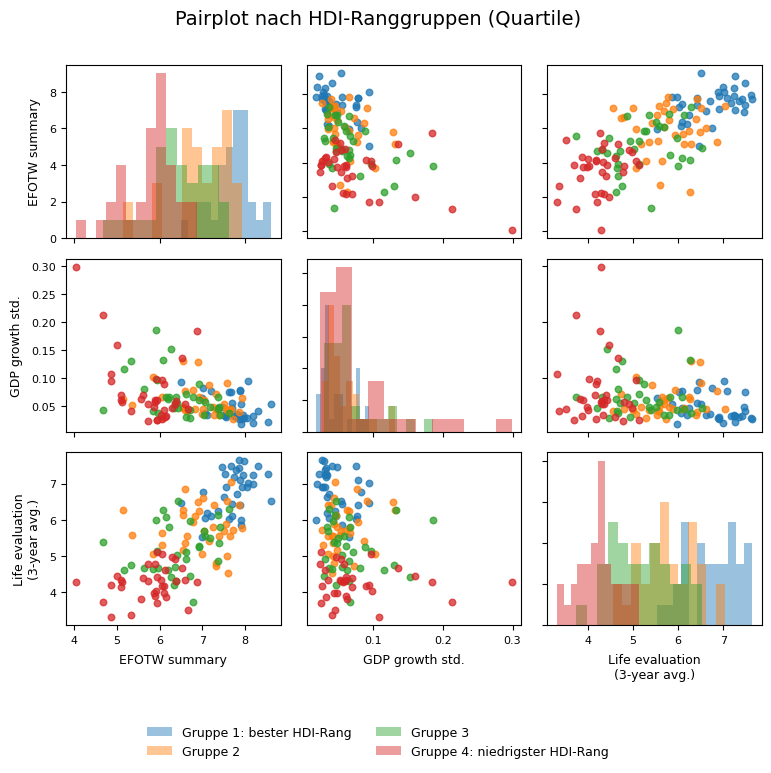

In [6]:
# HDI-Rang in vier gleich große Gruppen einteilen
# Niedriger hdi_rank = besserer Rang
merged["hdi_rank_group"] = pd.qcut(
    merged["hdi_rank"],
    q=4,
    labels=[
        "Gruppe 1: bester HDI-Rang",
        "Gruppe 2",
        "Gruppe 3",
        "Gruppe 4: niedrigster HDI-Rang",
    ],
)

# Variablen für den Pairplot auswählen
vars_to_plot = [
    "efotw_summary",
    "rgdpo_growth_std",
    "life_evaluation_(3-year_average)",
]

# Kürzere Labels, damit nichts überlappt
label_map = {
    "efotw_summary": "EFOTW summary",
    "rgdpo_growth_std": "GDP growth std.",
    "life_evaluation_(3-year_average)": "Life evaluation\n(3-year avg.)",
}

plot_df = merged[vars_to_plot + ["hdi_rank_group"]].dropna().copy()

# Quadratisches Format
n = len(vars_to_plot)
fig, axes = plt.subplots(n, n, figsize=(8, 8))

groups = plot_df["hdi_rank_group"].cat.categories

for i, y_var in enumerate(vars_to_plot):
    for j, x_var in enumerate(vars_to_plot):
        ax = axes[i, j]

        if i == j:
            # Diagonale: Histogramme
            for group in groups:
                subset = plot_df.loc[
                    plot_df["hdi_rank_group"] == group, x_var
                ]
                ax.hist(
                    subset,
                    bins=12,
                    alpha=0.45,
                    label=group
                )
        else:
            # Off-Diagonale: Scatterplots
            for group in groups:
                subset = plot_df.loc[
                    plot_df["hdi_rank_group"] == group
                ]
                ax.scatter(
                    subset[x_var],
                    subset[y_var],
                    s=22,
                    alpha=0.75,
                    label=group
                )

        # X-Achsen nur unten beschriften
        if i == n - 1:
            ax.set_xlabel(label_map[x_var], fontsize=9, labelpad=6)
            ax.tick_params(axis="x", labelsize=8, rotation=0)
        else:
            ax.set_xlabel("")
            ax.tick_params(axis="x", labelbottom=False)

        # Y-Achsen nur links beschriften
        if j == 0:
            ax.set_ylabel(label_map[y_var], fontsize=9, labelpad=6)
            ax.tick_params(axis="y", labelsize=8)
        else:
            ax.set_ylabel("")
            ax.tick_params(axis="y", labelleft=False)

# Titel
fig.suptitle(
    "Pairplot nach HDI-Ranggruppen (Quartile)",
    fontsize=14,
    y=0.97
)

# Gemeinsame Legende unten im Bild
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=2,
    frameon=False,
    fontsize=9
)

# Manuelle Abstände, damit Titel und Legende nicht überlappen
fig.subplots_adjust(
    left=0.11,
    right=0.98,
    top=0.90,
    bottom=0.20,
    wspace=0.12,
    hspace=0.12
)

# Quadratisch speichern: 8 x 8 inch bei 200 dpi = 1600 x 1600 px
fig.savefig(
    "pairplot_quadrat.png",
    dpi=200,
    facecolor="white"
)

plt.show()
